KMeans Silhouette: 0.360
Agglomerative Silhouette: 0.361
DBSCAN нашел только 1 кластер, попробуйте изменить eps.


C:\Users\ismai\AppData\Local\Temp\ipykernel_14992\3501944963.py:94: RuntimeWarning: invalid value encountered in scalar divide
  color = 'red' if label == -1 else plt.cm.viridis(label / max(unique_labels))


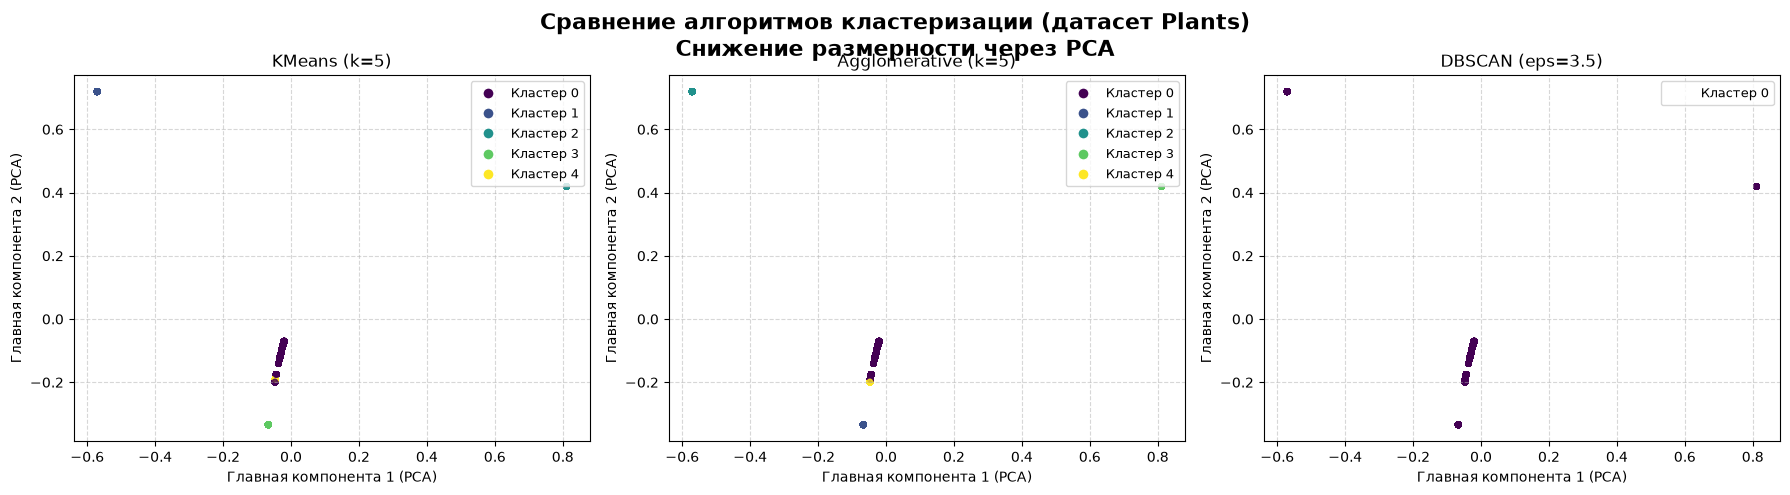

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 1. Парсинг данных (Чтение специфического формата plants.data)
with open('plants.data', 'r', encoding='utf-8', errors='ignore') as f:
    lines = f.readlines()

data = []
for line in lines:
    parts = line.strip().rsplit(',', 1) # Разделяем по ПОСЛЕДНЕЙ запятой
    if len(parts) == 2:
        plant_name, states_str = parts
        # Убираем пробелы и создаем список штатов
        states = [s.strip() for s in states_str.split(',') if s.strip()]
        data.append((plant_name, states))

# Создаем бинарную матрицу (One-Hot Encoding)
# Каждое уникальное растение - строка, каждый штат - колонка
df = pd.DataFrame(0, index=[d[0] for d in data], columns=list(set(s for d in data for s in d[1])))
for plant_name, states in data:
    df.loc[plant_name, states] = 1

X = df.values # Наша матрица признаков (0 и 1)

# 2. Масштабирование признаков (Scaling)
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# 3. Алгоритмы кластеризации
# KMeans
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled)

# Agglomerative (Иерархическая кластеризация)
agglo = AgglomerativeClustering(n_clusters=5, linkage='ward')
labels_agglo = agglo.fit_predict(X_scaled)

# DBSCAN (Плотностная кластеризация)
dbscan = DBSCAN(eps=1.5, min_samples=10) 
labels_dbscan = dbscan.fit_predict(X_scaled)

# 4. Оценка качества (Silhouette Score)
print(f"KMeans Silhouette: {silhouette_score(X_scaled, labels_kmeans):.3f}")
print(f"Agglomerative Silhouette: {silhouette_score(X_scaled, labels_agglo):.3f}")

# Для DBSCAN игнорируем шум (-1), чтобы корректно посчитать метрику
mask = labels_dbscan != -1
if len(set(labels_dbscan[mask])) > 1:
    print(f"DBSCAN Silhouette: {silhouette_score(X_scaled[mask], labels_dbscan[mask]):.3f} (шум: {list(labels_dbscan).count(-1)} растений)")
else:
    print("DBSCAN нашел только 1 кластер, попробуйте изменить eps.")

# 5. Визуализация (Снижаем размерность до 2D с помощью PCA для графика)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Настраиваем фигуру
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Сравнение алгоритмов кластеризации (датасет Plants)\nСнижение размерности через PCA', 
             fontsize=16, fontweight='bold')

# Список наших алгоритмов и их названий
models = [
    (labels_kmeans, 'KMeans (k=5)'),
    (labels_agglo, 'Agglomerative (k=5)'),
    (labels_dbscan, 'DBSCAN (eps=3.5)')
]

for ax, (labels, title) in zip(axes, models):
    # Строим scatter plot. 
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', s=15, alpha=0.8)
    
    # Подписи осей
    ax.set_xlabel('Главная компонента 1 (PCA)')
    ax.set_ylabel('Главная компонента 2 (PCA)')
    ax.set_title(title, fontsize=12)
    
    # Добавляем сетку для удобства
    ax.grid(True, linestyle='--', alpha=0.5)

    # Формируем легенду (ограничиваем количество элементов, если их слишком много)
    unique_labels = sorted(set(labels))
    if len(unique_labels) > 10:
        unique_labels = unique_labels[:10] # Берем только первые 10 для легенды

    handles = []
    for label in unique_labels:
        # Если метка -1 (шум в DBSCAN) - делаем её красной
        color = 'red' if label == -1 else plt.cm.viridis(label / max(unique_labels))
        label_name = 'Шум (выбросы)' if label == -1 else f'Кластер {label}'
        handles.append(plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color, 
                                  markersize=8, label=label_name))
    
    ax.legend(handles=handles, loc='upper right', fontsize=9)

plt.tight_layout()
plt.subplots_adjust(top=0.85) # Оставляем место для общего заголовка
plt.show()